# Exploring the Student Dropout dataset

Exploration done before training the models in `train_models.py`.

Dataset: UCI *Predict Students' Dropout and Academic Success*. Goal: predict whether a student will drop out, stay enrolled, or graduate, using only information available at enrollment and after the 1st semester.

In [2]:
%pip install scikit-learn==1.8.0

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# same loading steps as the training script
from train_models import data_load, CODED_CATEGORY_COLS, SECOND_SEM_COLS

raw = pd.read_csv("data/data.csv", sep=";")
raw.columns = raw.columns.str.strip()
df = data_load()   # 2nd-sem columns dropped, coded columns as text
print("Raw data:", raw.shape, "| After preparation:", df.shape)

Raw data: (4424, 37) | After preparation: (4424, 31)


## 1. First look at the data

In [5]:
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,14.000000,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,8,6,13.428571,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,9,5,12.333333,0,13.9,-0.3,0.79,Graduate


In [6]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [7]:
print("Missing values in total:", raw.isna().sum().sum())
print("Duplicate rows:", raw.duplicated().sum())

Missing values in total: 0
Duplicate rows: 0


**My observations:** _TODO: write 1–2 sentences on what you see in the output above._

## 2. How balanced are the outcomes?

Target
Graduate    49.9 %
Dropout     32.1 %
Enrolled    17.9 %
Name: count, dtype: object


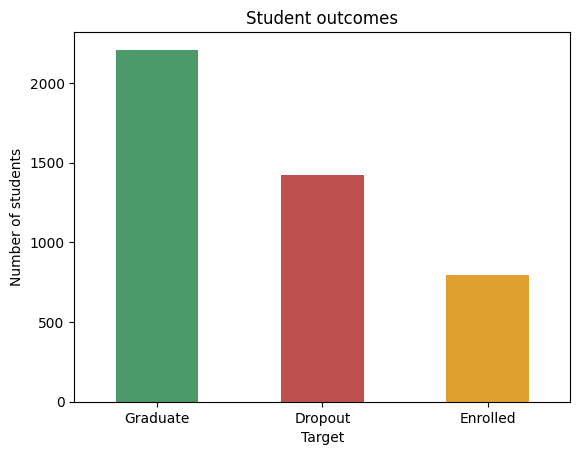

In [10]:
counts = df["Target"].value_counts()
print((counts / len(df) * 100).round(1).astype(str) + " %")

counts.plot(kind="bar", color=["#4C9A6A", "#C0504D", "#E0A030"], rot=0)
plt.title("Student outcomes")
plt.ylabel("Number of students")
plt.show()

**My observations:** _TODO: write 1–2 sentences on what you see in the output above._

_Hint: think about what a model that always predicts the largest class would score, and what that means for accuracy vs MCC._

## 3. First-semester performance by outcome

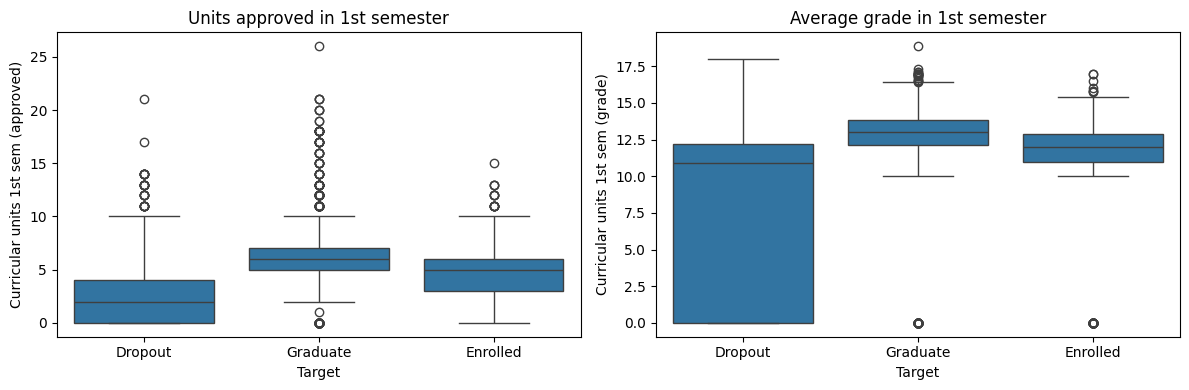

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Target", y="Curricular units 1st sem (approved)", ax=axes[0])
sns.boxplot(data=df, x="Target", y="Curricular units 1st sem (grade)", ax=axes[1])
axes[0].set_title("Units approved in 1st semester")
axes[1].set_title("Average grade in 1st semester")
plt.tight_layout()
plt.show()

**My observations:** _TODO: write 1–2 sentences on what you see in the output above._

_Hint: is the Enrolled group in between the other two, or does it overlap with one of them?_

## 4. Financial and personal factors

In [16]:
for col in ["Tuition fees up to date", "Debtor", "Scholarship holder"]:
    table = pd.crosstab(df[col], df["Target"], normalize="index").round(3) * 100
    print(f"\n{col} (% of students in each row)")
    print(table)


Tuition fees up to date (% of students in each row)
Target                   Dropout  Enrolled  Graduate
Tuition fees up to date                             
0                           86.6       8.0       5.5
1                           24.7      19.3      56.0

Debtor (% of students in each row)
Target  Dropout  Enrolled  Graduate
Debtor                             
0          28.3      18.0      53.8
1          62.0      17.9      20.1

Scholarship holder (% of students in each row)
Target              Dropout  Enrolled  Graduate
Scholarship holder                             
0                      38.7      20.0      41.3
1                      12.2      11.8      76.0


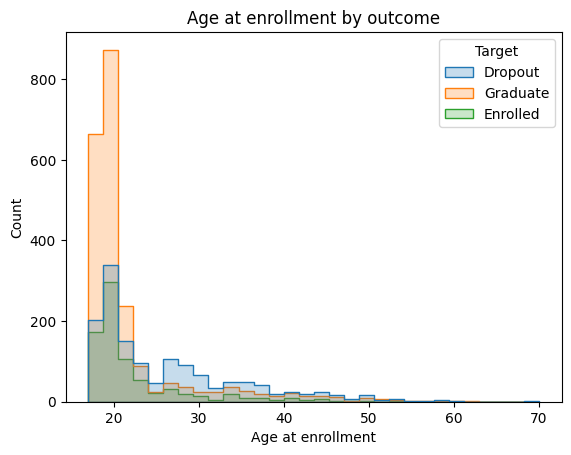

In [17]:
sns.histplot(data=df, x="Age at enrollment", hue="Target", bins=30, element="step")
plt.title("Age at enrollment by outcome")
plt.show()

**My observations:** _TODO: write 1–2 sentences on what you see in the output above._

## 5. How many categories do the coded columns have?

These columns are stored as numbers but are really category codes, so they are one-hot encoded in training.

In [20]:
df[CODED_CATEGORY_COLS].nunique().sort_values(ascending=False)

Father's occupation       46
Father's qualification    34
Mother's occupation       32
Mother's qualification    29
Nacionality               21
Application mode          18
Previous qualification    17
Course                    17
Marital status             6
dtype: int64

In [21]:
occ = df["Father's occupation"].value_counts()
print("Categories:", len(occ))
print("Categories with fewer than 10 students:", (occ < 10).sum())
occ.tail(10)

Categories: 46
Categories with fewer than 10 students: 32


Father's occupation
132    1
161    1
143    1
134    1
153    1
174    1
141    1
114    1
101    1
154    1
Name: count, dtype: int64

**My observations:** _TODO: write 1–2 sentences on what you see in the output above._

_Hint: how does this relate to Naive Bayes doing so badly with one-hot encoding?_

## 6. Are the features independent?

Naive Bayes assumes every feature is independent of the others given the class.

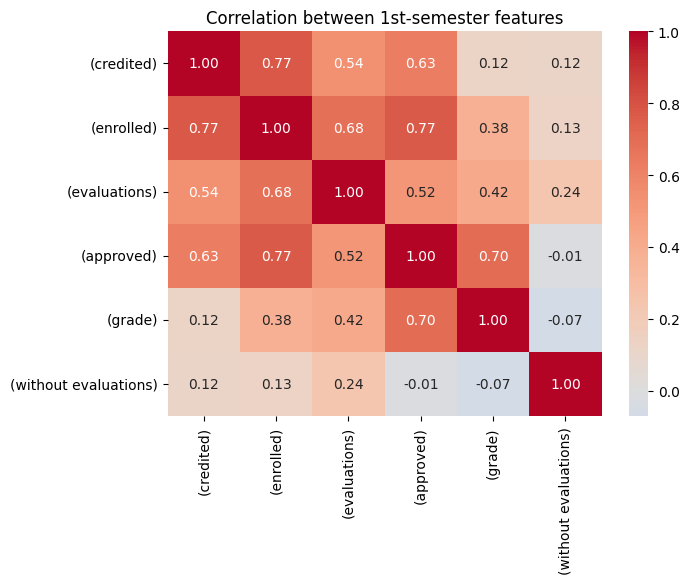

In [24]:
first_sem = [c for c in df.columns if "1st sem" in c]
plt.figure(figsize=(7, 5))
sns.heatmap(df[first_sem].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            xticklabels=[c.replace("Curricular units 1st sem ", "") for c in first_sem],
            yticklabels=[c.replace("Curricular units 1st sem ", "") for c in first_sem])
plt.title("Correlation between 1st-semester features")
plt.show()

**My observations:** _TODO: write 1–2 sentences on what you see in the output above._

## 7. Why drop the 2nd-semester columns?

In [27]:
print("Dropped columns:")
for c in SECOND_SEM_COLS:
    print(" -", c)

print("\nCorrelation between 1st and 2nd semester approved units:",
      round(raw["Curricular units 1st sem (approved)"].corr(raw["Curricular units 2nd sem (approved)"]), 3))

Dropped columns:
 - Curricular units 2nd sem (credited)
 - Curricular units 2nd sem (enrolled)
 - Curricular units 2nd sem (evaluations)
 - Curricular units 2nd sem (approved)
 - Curricular units 2nd sem (grade)
 - Curricular units 2nd sem (without evaluations)

Correlation between 1st and 2nd semester approved units: 0.904


**My observations:** _TODO: write 1–2 sentences on what you see in the output above._

_Hint: when would a university actually need this prediction, and what would it know at that point?_

## Summary

_TODO: 3–4 sentences pulling together what you learned, and how it shaped the choices in `train_models.py`._